In [1]:
import torch

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [11]:
x = torch.linspace(-2, 2, 50).unsqueeze(1)

In [6]:
x

tensor([[-2.0000],
        [-1.9664],
        [-1.9328],
        [-1.8992],
        [-1.8655],
        [-1.8319],
        [-1.7983],
        [-1.7647],
        [-1.7311],
        [-1.6975],
        [-1.6639],
        [-1.6303],
        [-1.5966],
        [-1.5630],
        [-1.5294],
        [-1.4958],
        [-1.4622],
        [-1.4286],
        [-1.3950],
        [-1.3613],
        [-1.3277],
        [-1.2941],
        [-1.2605],
        [-1.2269],
        [-1.1933],
        [-1.1597],
        [-1.1261],
        [-1.0924],
        [-1.0588],
        [-1.0252],
        [-0.9916],
        [-0.9580],
        [-0.9244],
        [-0.8908],
        [-0.8571],
        [-0.8235],
        [-0.7899],
        [-0.7563],
        [-0.7227],
        [-0.6891],
        [-0.6555],
        [-0.6218],
        [-0.5882],
        [-0.5546],
        [-0.5210],
        [-0.4874],
        [-0.4538],
        [-0.4202],
        [-0.3866],
        [-0.3529],
        [-0.3193],
        [-0.2857],
        [-0.

In [17]:
# Créer un bruit aléatoire pour les données
noise = 0.6*torch.randn_like(x)
y = 3 * x + 2 + noise

In [8]:
import matplotlib.pyplot as plt
import numpy as np

In [9]:
import numpy as np
print(np.__version__)

1.26.4


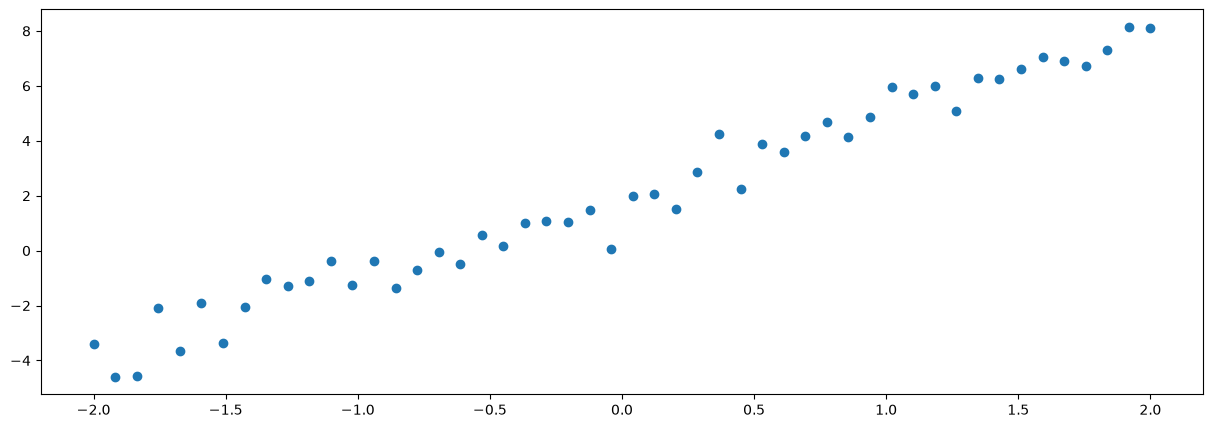

In [18]:
plt.figure(figsize=(15, 5))
plt.scatter(x, y)

In [19]:
import torch.nn as nn


In [20]:
model = nn.Linear(1, 1)

In [36]:
# Trainning the model 
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
epochs = 500
losses = []
for epoch in range(epochs):
    y_pred = model(x)
    loss = loss_function(y, y_pred)
    optimizer.zero_grad() # Initialiser les gradient à zero 
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 == 0 :
        print(f"Epoch : {epoch} / {epochs}, loss : {loss.item()}") # Afficher le loss à chaque 100 epochs

Epoch : 0 / 500, loss : 0.386759877204895
Epoch : 100 / 500, loss : 0.3867602050304413
Epoch : 200 / 500, loss : 0.38675978779792786
Epoch : 300 / 500, loss : 0.38675978779792786
Epoch : 400 / 500, loss : 0.38675978779792786


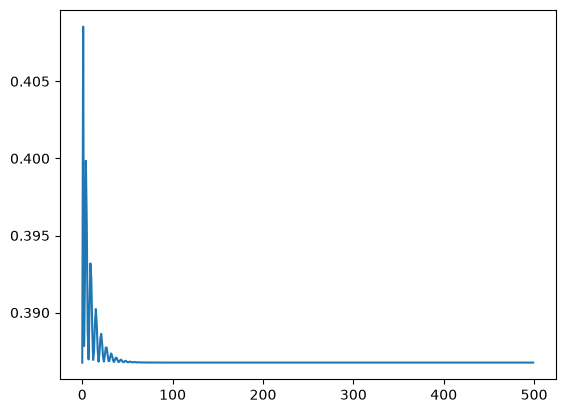

In [37]:
plt.plot(losses)

In [31]:
with torch.inference_mode():
    pred = model(x)

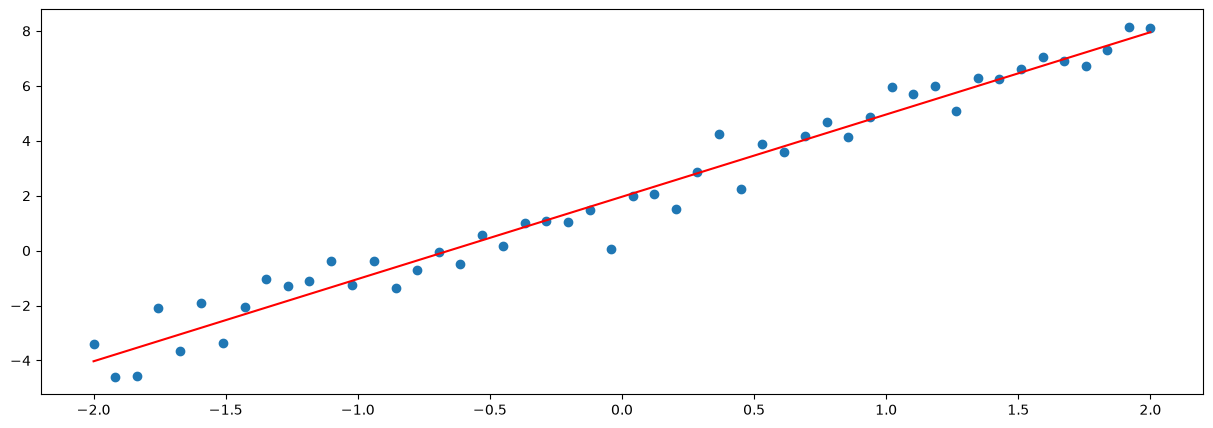

In [32]:
plt.figure(figsize=(15, 5))
plt.scatter(x, y)
plt.plot(x, pred, color="red")

In [26]:
from torcheval.metrics import R2Score 

In [33]:
# Calcule du taux de détermination (R²) pour évaluer la performance du modèle
r2_score = R2Score()
r2_score.update(y,pred)
score = r2_score.compute()


In [34]:
print(score)

tensor(0.9689)
